In [ ]:
from sklearn.datasets import fetch_openml
import torch
import numpy as np
from matplotlib import pyplot as plt
from torch.utils.tensorboard import SummaryWriter

*Lezione 0*

In [ ]:
#! primi utilizzi di torch


x = torch.tensor([3.0], requires_grad=True)
#? con requires_grad sto dicendo a python che voglio che tenga traccia delle operazioni effettuate su queste variabili,
#? perché successivamente voglio calcolare le derivate rispetto a esse.

print("Tensore:", x)
print("Gradiente iniziale:", x.grad)
print("Funzione generatrice:", x.grad_fn)

y =2*x**2

print(y)
print(y.grad_fn)
y.backward()
#? calcola la derivata della funzione y
#? sostituisce il valore del "tensore" x al suo interno
#? la derivata di y è 4x sostituendo con x = 3 otteniamo 12
print(x.grad)

In [ ]:
#! calcolo gradiente funzione multiparametro

f = lambda x,y,z : (x**2-1/y)/z
x = torch.Tensor([3]); x.requires_grad_(True)
y = torch.Tensor([2]); y.requires_grad_(True)
z = torch.Tensor([3]); z.requires_grad_(True)

result = f(x,y,z)
result.backward()
print("%0.2f" % x.grad)
print("%0.2f" % y.grad)
print("%0.2f" % z.grad)
#? stiamo calcolando il gradiente (guarda teoria) nel caso multiparametro


In [ ]:
#! Esempio di calcolo del gradiente di una funzione più complicata
x=torch.Tensor([1])
y=torch.Tensor([5])
z=torch.Tensor([2])
p=torch.Tensor([5])
q=torch.Tensor([6])

x.requires_grad_(True)
y.requires_grad_(True)
z.requires_grad_(True)
p.requires_grad_(True)
q.requires_grad_(True)

a=x+2*y+3*z
b=a*p
c=b/q

c.backward(); #senza specificare nulla verrano calcolati i gradienti di tutte le variabili
# con b=a.detach()*p non vengono calcolati i gradienti di x, y e z (viene usato questo approccio in quanto potrebbe essere poco utile farlo)

print(x.grad)
print(y.grad)
print(z.grad)
print(p.grad)
print(q.grad)

#? Calcoliamo l'influenza locale di ciascun parametro
#? sul risultato finale c attraverso il gradiente.

In [ ]:
#! Esercizio 11
x=torch.Tensor([0])
y=torch.Tensor([8])
x.requires_grad_(True)
y.requires_grad_(True)

r = x/y**x - y**3

r.backward();

print(x.grad);
print(y.grad);


*Lezione 1*

Sviluppiamo la regressione lineare, di seguito le formule importanti: 
- Regressione: $y(x) = θ_1x_1 + … + θ_{13}x_{13} + θ_0 $
- MSE: $\mathcal{L}_{\theta}(\hat{\mathbf{y}}, \mathbf{y}) = \mathcal{L}_{\theta}(\mathbf{x}, \mathbf{y}) = \frac{1}{N}\sum_{i}^{N}\left(\theta_0 + \sum_i(x_i\theta_i) - y_i\right)^2$
- Aggiornamento pesi: $\theta = \theta - \eta \nabla_{\theta} \mathcal{L}_{\theta}(\hat{\mathbf{y}}, \mathbf{y})$
- derivata MSE: $\frac{\partial L}{\partial\theta} =\frac{2}{N}\sum_{i=1}^{N}(\hat y_i-y_i)x_i$

In [ ]:
#! Ci prepariamo ad allenare un regressore - definiamo il dataset

# Prendiamo i dati del dataset boston (ci sono diverse informazioni su delle case a boston)
from sklearn.datasets import fetch_openml
boston = fetch_openml(name='boston', version=1)

X = boston.data.to_numpy().astype(float) #varie informazioni sulla casa (13 colonne)
Y = boston.target.to_numpy().astype(float) # i valori di ogni casa in multipli di 1000$

np.random.seed(123)
torch.random.manual_seed(123)
idx = np.random.permutation(len(X)) # genera una sequenza di indici senza ripetizioni

# riordinano gli array seguendo gli indici generati in idx, ci permette di mescolare i dati
X = X[idx]
Y = Y[idx]

# Dividiamo il dataset in dati di training e dati di testing (avendo mescolato non abbiamo alcun bias)
X_training = torch.Tensor(X[50:])
Y_training = torch.Tensor(Y[50:])
X_testing = torch.Tensor(X[:50])
Y_testing = torch.Tensor(Y[:50])



In [76]:
# Funzione Linear Regression

# Funzione che va a fare la vera e propria regressione in output y(x)
def linear_regression(input, theta, theta_0):
    return input.mul(theta).sum(1)+theta_0
    #input.mul(theta) -> moltiplica le feature per i valori di theta
    #.sum(1) -> fa la somma di tutte le colonne (le colonne sono di indice 1)
    #+theta_0 aggiunge theta di 0

In [77]:
# Funzione MSE

# Definiamo la funzione MSE, ci dirà il nostro valore di errore medio
def loss(input, target):
    return ((input-target)**2).mean()

In [ ]:
#! Ci prepariamo ad allenare un regressore - definiamo il modello
#vogliamo usare un regressore lineare semplice, guarda la formula nella teoria

theta = torch.Tensor(13) #creiamo un tensore con 13 unità (array con 13 posti)
theta_0 = torch.Tensor(1) # intercetta della retta, quanto vale y se x = 0 (in questo caso vale 1)
theta.requires_grad_(True)
theta_0.requires_grad_(True)
theta.data.normal_(0,0.1) #inizializzazione con valori casuali presi da una gaussiana con varianza 0.1
theta_0.data.normal_(0,0.1)



tensor([-0.1384])

In [ ]:
#! Prima regressione
y = linear_regression(X_training, theta, theta_0) # vettore delle etichette stimate
print(y[:10])
print(Y_training[:10])

# Questa è la nostra prima regressione con valori di theta casuali, notiamo nel risultato come i valori predetti e quelli ground truth sono molto diversi
# di conseguenza la loss è molto alta

print(loss(y,Y_training)) # Ricordiamo che y sarrebbe ŷ

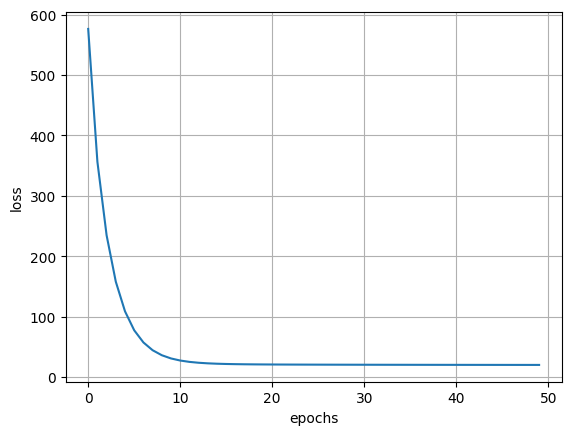

tensor(42.8986, grad_fn=<MeanBackward0>)


In [93]:
#! La discesa del gradiente

lr = 0.1 # learning rate
epochs = 50 #numero di addestramenti

#normalizzazione dei dati
means = X_training.mean(0)
stds = X_training.std(0)
X_training_norm = (X_training-means)/stds
X_testing_norm = (X_testing-means)/stds

#inizializziamo i pesi come visto in precedenza
theta = torch.Tensor(13);
theta_0 = torch.Tensor(1);
theta.normal_(0,0.01)
theta_0.normal_(0,0.01)
theta.requires_grad_(True)
theta_0.requires_grad_(True)

losses = []
#! La discesa del gradiente

lr = 0.1 # learning rate
epochs = 50 #numero di addestramenti

#normalizzazione dei dati
means = X_training.mean(0)
stds = X_training.std(0)
X_training_norm = (X_training-means)/stds
X_testing_norm = (X_testing-means)/stds

#inizializziamo i pesi come visto in precedenza
theta = torch.Tensor(13);
theta_0 = torch.Tensor(1);
theta.normal_(0,0.01)
theta_0.normal_(0,0.01)
theta.requires_grad_(True) #Tiene anche traccia delle operazioni che hanno prodotto quel risultato e delle informazioni necessarie per calcolare le derivate.
theta_0.requires_grad_(True)

losses = []

for e in range(epochs):
    #Passo 3: calcoliamo le predizioni
    y = linear_regression(X_training_norm,theta,theta_0)

    #Passo 4: calcoliamo il valore della loss
    l = loss(y, Y_training)
    losses.append(l.item())

    #Passo 5: calcoliamo il gradiente della loss rispetto a tutti i parametri
    l.backward()
    # fa la derivata della funzione di loss
    # e ci sostituisce i valori usati per il calcolo della loss stessa
    # pytorch ha queste informazioni grazie a requires_grad
    # il risultato è il gradiente di ogni parametro

    #stampiamo il valore della loss
    # print("Epoch: {}, loss: {:0.2f}".format(e,l.item()))

    #Aggiorniamo i pesi
    theta.data.sub_(lr*theta.grad.data)
    theta_0.data.sub_(lr*theta_0.grad.data)

    #azzeriamo i gradienti per evitare di accumularli
    theta.grad.data.zero_()
    theta_0.grad.data.zero_()

plt.figure()
plt.plot(losses)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.grid()
plt.show()

# Dopo circa 20 epoche i pesi sono ottimizzati e quindi la loss è bassa, stiamo ragionando sulla loss di training, vediamo sul dataset di test

yt = linear_regression(X_testing_norm,theta,theta_0)
print(loss(yt, Y_testing))
# è il doppio del dataset di training, c'è dell'overfitting

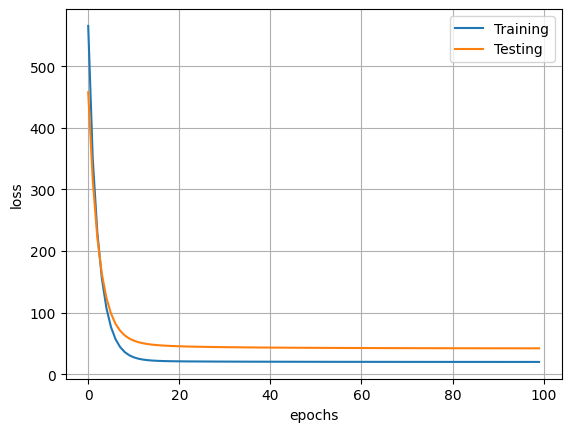

In [94]:
# Usiamo pytorch per fare lo stesso, in modo automatico
from torch import nn

class LinearRegressor(nn.Module):
    def __init__(self, in_size, out_size):
        """Costruisce un regressore logistico.
        Input:
        in_size: numero di feature in input (es. 13)
        out_size: numero di elementi in output (es. 1)"""
        super(LinearRegressor, self).__init__() #richiamo il costruttore della superclasse
        #questo passo è necessario per abilitare alcuni meccanismi automatici dei moduli di PyTorch
        self.linear = nn.Linear(in_size,out_size)
    def forward(self,x):
        """Definisce come processare l'input x"""
        result = self.linear(x)
        return result


lr = 0.1
epochs = 100
#normalizzazione dei dati
means = X_training.mean(0)
stds = X_training.std(0)
X_training_norm = (X_training-means)/stds
X_testing_norm = (X_testing-means)/stds

reg = LinearRegressor(13,1)
criterion = nn.MSELoss() #la loss è spesso riferita come "criterio" di ottimizzazione
optimizer = torch.optim.SGD(reg.parameters(),lr=lr) #l'optimizer vuole un riferimento ai parametri da ottimizzare e il learning rate

losses_train = []
losses_test = []
for e in range(epochs):
    #mettiamo il regressore in modalità training
    reg.train()
    output = reg(X_training_norm)
    l = criterion(output.view(-1),Y_training)
    losses_train.append(l.item())
    l.backward()
    optimizer.step()
    optimizer.zero_grad()
    #calcoliamo la loss di test
    #mettiamo il modello in modalità validation
    reg.eval()
    with torch.set_grad_enabled(False):
        y_test=reg(X_testing_norm)
        l = criterion(y_test.view(-1),Y_testing)
        losses_test.append(l.item())

from matplotlib import pyplot as plt
plt.figure()
plt.plot(losses_train)
plt.plot(losses_test)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.grid()
plt.legend(['Training','Testing'])
plt.show()

In [87]:
# Vediamo come monitorare la procedura di training

# usiamo tensorboard, usiamo il comando tensorboard --logdir logs

from torch.utils.tensorboard import SummaryWriter
writer = SummaryWriter('logs/test0')

#simuliamo un ciclo di training
for global_step in range(10):
    writer.add_scalar('loss/train', np.sin(global_step/5*3.14), global_step=global_step)
#simuliamo un valore di test
    writer.add_scalar('loss/test', 1, global_step=global_step)
#simuliamo un secondo ciclo di training
for global_step in range(10, 20):
    writer.add_scalar('loss/train', np.sin(global_step/5*3.14), global_step=global_step)
    #simuliamo un secondo valore di test
    writer.add_scalar('loss/test', 0.5, global_step=global_step)

In [100]:
# genera dei grafici interessanti da vedere
lr = 0.001
epochs = 5000
writer = SummaryWriter('logs/linear_regressor0.001')
#normalizzazione dei dati
means = X_training.mean(0)
stds = X_training.std(0)
X_training_norm = (X_training-means)/stds
X_testing_norm = (X_testing-means)/stds

reg = LinearRegressor(13,1)
criterion = nn.MSELoss() #la loss è spesso riferita come "criterio" di ottimizzazione
optimizer = torch.optim.SGD(reg.parameters(),lr=lr) #l'optimizer vuole un riferimento ai parametri da ottimizzare e il learning rate

for e in range(epochs):
    #mettiamo il regressore in modalità training
    reg.train()
    output = reg(X_training_norm)
    l = criterion(output.view(-1),Y_training)
    writer.add_scalar('loss/train', l.item(), global_step=e)
    l.backward()
    optimizer.step()
    optimizer.zero_grad()
    #calcoliamo la loss di test
    #mettiamo il modello in modalità validation
    reg.eval()
    with torch.set_grad_enabled(False):
        y_test=reg(X_testing_norm)
        l = criterion(y_test.view(-1),Y_testing)
        writer.add_scalar('loss/test', l.item(), global_step=e)